For the basal ganglia manuscript paper - in revision

Approach similar to StrioMat figure:
- DAPI
- Marker gene transcripts
- Segmentation polygons

Cell types (suggested by Brian):
- SPN of some kind (medium)
- Cholinergic cells (big)
- ICj (small)

In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys
sys.path.append("/code")
from bg_spatial_plots.constants_color_palettes import CURRENT_COLOR_DICT_OF_DICTS

import json
from pathlib import Path

import anndata as ad
import geojson
import geopandas as gpd
from spatialdata_io import merscope, xenium, xenium_aligned_image
import spatialdata as sd
import spatialdata_plot  # noqa: F401
from spatialdata.transformations import (
    Affine,
    MapAxis,
    Scale,
    Sequence,
    Translation,
    get_transformation,
    set_transformation,
    remove_transformations_to_coordinate_system
)

import matplotlib as mpl
import matplotlib.patches as patches
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from spatialdata.models import ShapesModel, TableModel

import numpy as np
import pandas as pd

from bg_spatial_plots.spatialdata_utils import apply_transform_to_merscope_sdata, render_shapes_outline_by_column, cache_and_load_merscope_zarr
from bg_spatial_plots.figure_utils import add_fonts_to_manager

In [2]:
# to use Arial
add_fonts_to_manager()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams.update({'font.size': 12})

# Use the BG taxonomy colors for cell types
#group_colors = CURRENT_COLOR_DICT_OF_DICTS["Group"]
#group_colors["Adjacent"] = "#D3D3D3"

# TODO: figure out where Group short names are stored so I don't have to separately attach this file
# use the BG taxonomy colors for cell types
bg_annot = pd.read_csv('/data/BG_annotation_sheet/HMBA_BG_consensus_annotation - consensus_anno_pre-print(1).csv', index_col=0)
group_colors = bg_annot.loc[:, 'color_hex_group'].to_dict()
if 'Adjacent' not in bg_annot.index:
    bg_annot = pd.concat([bg_annot, pd.DataFrame({'Group': ['Adjacent'], 'short_name_group': ['Adjacent']}).set_index('Group')])
group_colors['Adjacent'] = 'lightgrey'

In [3]:
# archive of combos that work
barcode_to_test = '1291811989'

In [4]:
# Point to the region_0 subdirectory where the actual data files are
merscope_dir = Path(f'/data/mfishmerscopemacaqueatlas/{barcode_to_test}/region_0')
sdata = cache_and_load_merscope_zarr(barcode_to_test, merscope_dir)

barcode_csv = pd.read_csv('/data/mac_merscope_barcodes/BM1205_coverslips_clean_14.csv', index_col=0)

# some hacks to get around transform filenames missing a period
spec_name = barcode_csv.loc[barcode_csv['Barcode'] == int(barcode_to_test), 'SpecimenName']
donor = spec_name.str.rsplit('.', n=5).values[0][0]
spec_split = spec_name.str.rsplit('.', expand=True)
slab = spec_split[3].values[0] + spec_split[4].values[0]
set_ = spec_split[6].values[0]

new_cs = 'global'  # makes plotting less complicated if we only have one coordinate system
apply_transform_to_merscope_sdata(sdata, barcode_to_test, spec_name.values[0], donor, slab, new_cs, rescale=20)

In [5]:
# TODO: this part should be possible using SIS, but I get an error when doing so
# so I just pilfered the part of the code I needed for myself
# should make an Issue and/or PR eventually

polygon_file = f'/data/mac_merscope_segmented_data/{barcode_to_test}/segmentation/cellpose1/cell_polygons.geojson'
with open(polygon_file) as f:
    features = geojson.load(f)

# this is an older dataset and we need to fix some things about how features are formatted
# e.g. ids are in features instead of properties
if 'z_plane' in features['features'][0].keys():
    features = geojson.FeatureCollection([{"geometry": feature["geometry"],
                                            "id": feature["id"],
                                            "properties": {'z_plane': feature['z_plane'], **feature['properties']},
                                            } for feature in features["features"]])

else:
    raise NotImplementedError('z_plane not in features - segmentation output not supported')

gdf = gpd.GeoDataFrame.from_features(features)
gdf['old_id'] = [feat['id'] for feat in features['features']]

# match SpotTable ids with cell labels
adata_og = ad.read_h5ad(f'/data/mac_merscope_segmented_data/{barcode_to_test}/segmentation/cellpose1/cell_by_gene.h5ad')
id_to_cell_label = dict(zip(adata_og.obs['SpotTable_cell_id'], adata_og.obs_names))
gdf['id'] = gdf['old_id'].astype(int).map(id_to_cell_label)
gdf['cell_label'] = gdf['id']
gdf = gdf.set_index('id')

# subset by z_plane to prevent duplicate cell values in index
# the image only includes z3 by default so this is fine for now
gdf = gdf[gdf['z_plane'].astype(float) == 3]

# add cell type labels to Table, polygons to Shapes
mapping_file = f'/data/mac_merscope_mapping_output/mapping_output/{barcode_to_test}_final.h5ad'
adata = ad.read_h5ad(mapping_file)

adata.obs['cell_label'] = adata.obs_names
adata.obs['cell_region'] = 'resegmented_polygons'
adata.uns['spatialdata_attrs'] = {'region': 'resegmented_polygons', 'region_key': 'cell_region', 'instance_key': 'cell_label'}

sdata['mapping_results'] = TableModel.parse(adata)
sdata['resegmented_polygons'] = ShapesModel.parse(gdf[~gdf['geometry'].isna()])

shapes_trans = get_transformation(sdata[f'{barcode_to_test}_region_0_polygons'])
set_transformation(sdata['resegmented_polygons'], shapes_trans)

/opt/conda/lib/python3.12/site-packages/spatialdata/models/models.py:1235: UserWarning: Converting `region_key: cell_region` to categorical dtype.
  convert_region_column_to_categorical(adata)


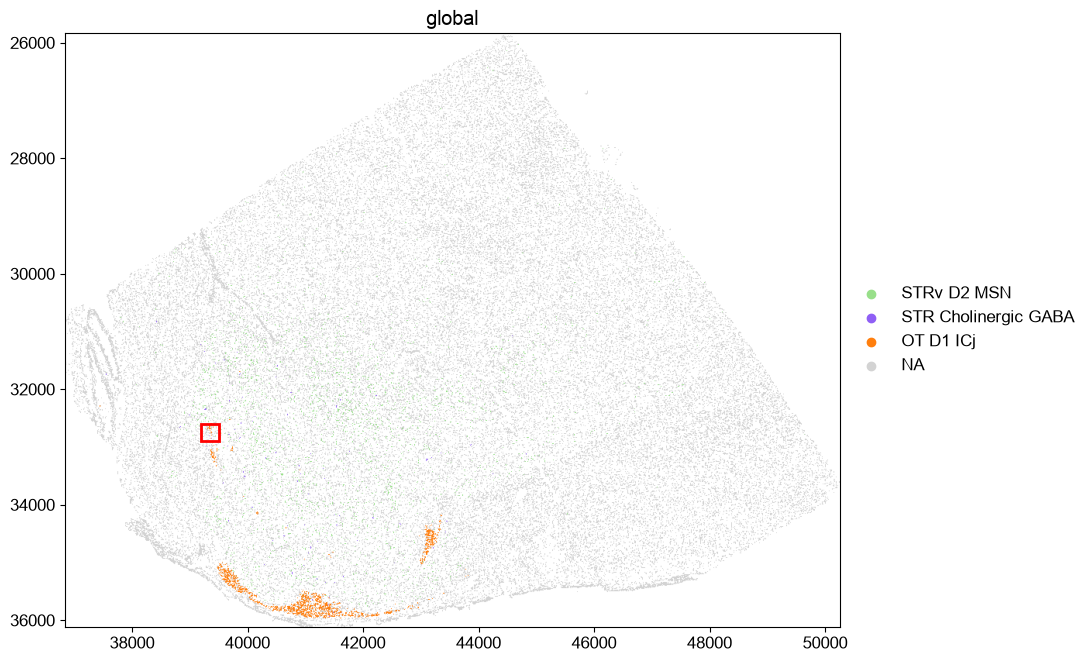

In [7]:
# bounding box
bb_xmin = 39200
bb_ymin = 32600
bb_w = 300
bb_h = 300
bb_xmax = bb_xmin + bb_w
bb_ymax = bb_ymin + bb_h

fig, ax = plt.subplots(figsize=(10,10))
sdata.pl.render_shapes(element='resegmented_polygons', palette=group_colors, color='Group_label', groups=['STRv D2 MSN', 'STR Cholinergic GABA', 'OT D1 ICj'], na_color='lightgrey').pl.show(ax=ax)
rect = patches.Rectangle((bb_xmin, bb_ymin), bb_w, bb_h, linewidth=2, edgecolor="red", facecolor="none")
ax.add_patch(rect)

/opt/conda/lib/python3.12/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


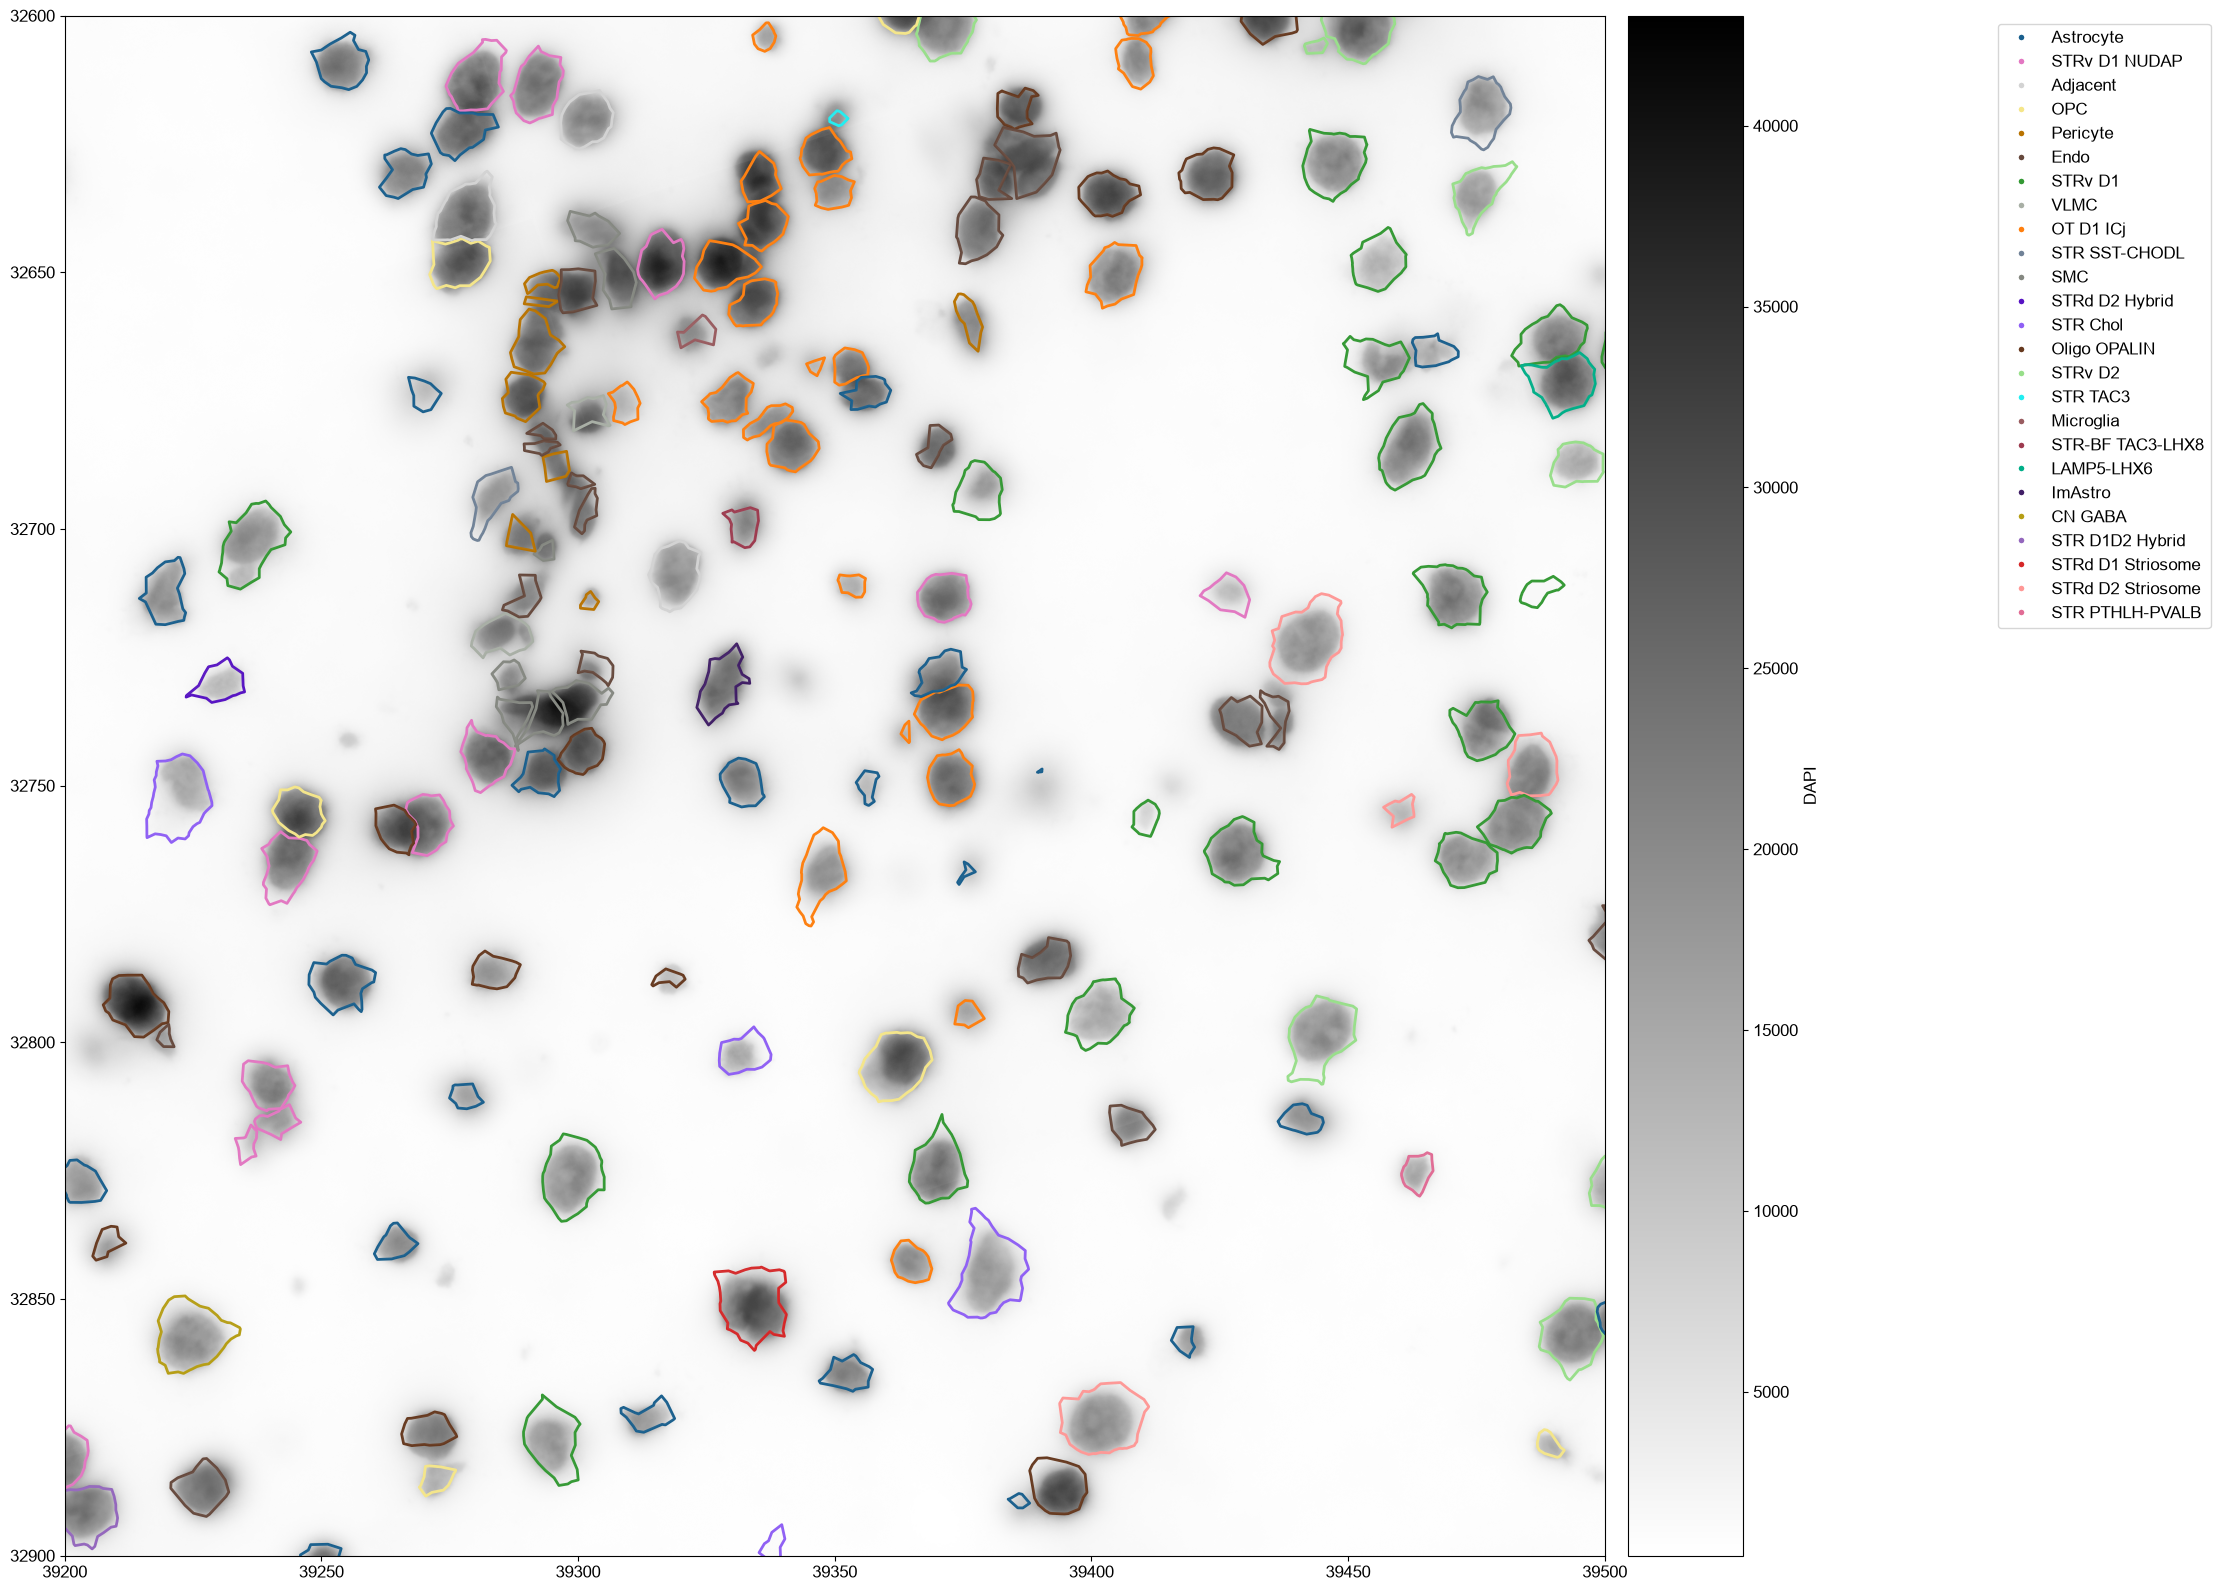

In [8]:
# to fix a bug with EntityID
# TODO: fix in cached zarr
sdata["table"].obs.index.name = None

# crop to a subregion
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],
    target_coordinate_system="global",
)

fig, ax = plt.subplots(figsize=(20,20))

# Render the image
cropped_sdata.pl.render_images(
    channel='DAPI', 
    element=f'{barcode_to_test}_region_0_z3', 
    cmap='grey_r',
    scale='full',
    colorbar=True,
).pl.show(ax=ax)

# Render colored outlines
render_shapes_outline_by_column(
    sdata=cropped_sdata,
    ax=ax,
    shapes_element='resegmented_polygons',
    table_name='mapping_results',
    color_column='Group_label',
    palette=group_colors,
    fill_alpha=0.05,
    outline_width=2
)

# Get unique cell types in the current subset
present_celltypes = cropped_sdata.tables['mapping_results'].obs['Group_label'].unique()
present_celltypes = [bg_annot.loc[ct, 'short_name_group'] for ct in present_celltypes]
group_colors_sn = {bg_annot.loc[ct, 'short_name_group']: color for ct, color in group_colors.items()}
legend_elements = [Line2D([0], [0], marker='.', color='w', 
                          markerfacecolor=group_colors_sn[ct], markersize=10, label=ct)
                   for ct in present_celltypes if ct in group_colors_sn]

ax.set_title('')
ax.set_xlim(bb_xmin, bb_xmax)
ax.set_ylim(bb_ymin, bb_ymax)
#ax.tick_params(left=False, bottom=False, labelbottom=False, labelleft=False)
ax.invert_yaxis()
ax.legend(handles=legend_elements, bbox_to_anchor=(1.25, 1), loc='upper left')

#plt.savefig('/results/macaque_StrioMat_lg_crop.svg')
plt.show()

/opt/conda/lib/python3.12/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


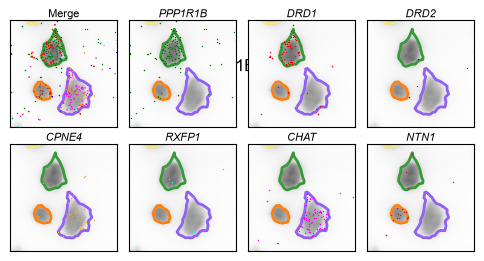

In [9]:
# crop to single cell
bb_xmin = 39350
bb_ymin = 32810
bb_w = 50
bb_h = 50
bb_xmax = bb_xmin + bb_w
bb_ymax = bb_ymin + bb_h

# crop to a subregion
sc_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],
    target_coordinate_system="global",
)

# Plot a single cell multiple times
# Define genes and their colors
genes =  ["PPP1R1B", "DRD1", "DRD2", "CPNE4", "RXFP1", "CHAT", "NTN1"]
gene_palette = {
    'PPP1R1B': 'green',
    "DRD1": 'red',
    "DRD2": 'blue',
    "CPNE4": 'orange',
    'CHAT': 'magenta',
    'RXFP1': 'cyan',
    'NTN1': 'brown'
}

# Create 2x4 subplot grid (8 subplots: 1 combined + 7 individual genes)
#fig, axes = plt.subplots(2, 4, figsize=(5, 2.5), 
#                         gridspec_kw={'wspace': 0.1, 'hspace': 0.15})
fig, axes = plt.subplots(2, 4, figsize=(6, 3), 
                         gridspec_kw={'wspace': 0.1, 'hspace': 0.15})
#plt.subplots_adjust(right=0.85)

axes = axes.flatten()

# Calculate DAPI intensity range from the LARGER crop to match contrast
# Use the cropped_sdata from the previous cell
dapi_img_large = np.array(cropped_sdata.images[f'{barcode_to_test}_region_0_z3']['scale0'].sel(c='DAPI').image)
vmin = dapi_img_large.min()
vmax = dapi_img_large.max()

# Function to render DAPI + cell boundaries on an axis
def render_base_layers(ax):
    sc_sdata.pl.render_images(
        channel='DAPI', 
        element=f'{barcode_to_test}_region_0_z3', 
        cmap='grey_r',
        norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax),
        scale='full',
        colorbar=False,
    ).pl.show(ax=ax)
    
    render_shapes_outline_by_column(
        sdata=sc_sdata,
        ax=ax,
        shapes_element='resegmented_polygons',
        table_name='mapping_results',
        color_column='Group_label',
        palette=group_colors,
        fill_alpha=0.05,
        outline_width=2
    )

# Subplot 0: Combined (all genes) - plot PPP1R1B first, then others on top
ax = axes[0]
render_base_layers(ax)
# Plot PPP1R1B first (bottom layer)
sc_sdata.pl.render_points(
    size=1, alpha=1, method='matplotlib', 
    color="gene", groups=['PPP1R1B'], 
    palette={'PPP1R1B': gene_palette['PPP1R1B']}
).pl.show(ax=ax)
# Plot other genes on top
other_genes = [g for g in genes if g != 'PPP1R1B']
sc_sdata.pl.render_points(
    size=1, alpha=1, method='matplotlib', 
    color="gene", groups=other_genes, 
    palette={g: gene_palette[g] for g in other_genes}
).pl.show(ax=ax)
# Remove auto-generated legend
if ax.get_legend():
    ax.get_legend().remove()
ax.set_xlim(bb_xmin, bb_xmax)
ax.set_ylim(bb_ymin, bb_ymax)
ax.tick_params(left=False, bottom=False, labelbottom=False, labelleft=False)
ax.invert_yaxis()
ax.set_title('Merge', fontsize=8, pad=2)

# Subplots 1-7: Individual genes
for i, gene in enumerate(genes, start=1):
    ax = axes[i]
    render_base_layers(ax)
    sc_sdata.pl.render_points(
        size=1, alpha=1, method='matplotlib', 
        color="gene", groups=[gene], 
        palette={gene: gene_palette[gene]}
    ).pl.show(ax=ax)
    # Remove auto-generated legend
    if ax.get_legend():
        ax.get_legend().remove()
    ax.set_xlim(bb_xmin, bb_xmax)
    ax.set_ylim(bb_ymin, bb_ymax)
    ax.tick_params(left=False, bottom=False, labelbottom=False, labelleft=False)
    ax.invert_yaxis()
    ax.set_title(gene, fontsize=8, pad=2, style='italic')

#plt.savefig('/results/macaque_StrioMat_sc_crop.svg', bbox_inches='tight')
#plt.savefig('/results/macaque_StrioMat_sc_crop.png', bbox_inches='tight', dpi=300)
plt.show()